In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/SOC_Project/"

oc = pd.read_csv(path + "wosis_202312_orgc.tsv", sep="\t")
prof = pd.read_csv(path + "wosis_202312_profiles.tsv", sep="\t")
layers = pd.read_csv(path + "wosis_202312_layers.tsv", sep="\t")

print("orgc:", oc.shape)
print(list(oc.columns))
print("profiles:", prof.shape)
print(list(prof.columns))
print("layers:", layers.shape)
print(list(layers.columns))

/tmp/ipykernel_4497/1367496876.py:5: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  oc = pd.read_csv(path + "wosis_202312_orgc.tsv", sep="\t")
/tmp/ipykernel_4497/1367496876.py:6: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  prof = pd.read_csv(path + "wosis_202312_profiles.tsv", sep="\t")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/SOC_Project/wosis_202312_layers.tsv'

In [ ]:
import os
print(os.listdir("/content/drive/MyDrive"))


['Colab Notebooks', 'IMG-20241217-WA0011.jpg', 'Introduction_to_Cybersecurity_Badge20241224-26-eaczyt.pdf', 'Screenshot_2024-12-24-14-42-38-28_6012fa4d4ddec268fc5c7112cbb265e7.jpg', 'Ethical_Hacker_Badge20241228-25-4c6ft7 (1).pdf', 'Ethical_Hacker_Badge20241228-25-4c6ft7.pdf', '2024-12-29 20-31-35.pdf', '2024-12-29 20-33-29.pdf', 'Module 3', 'Screenshot_2025-09-09-21-28-53-69_99c04817c0de5652397fc8b56c3b3817.jpg', 'Screenshot_2025-09-09-21-29-02-30_99c04817c0de5652397fc8b56c3b3817.jpg', 'my id.pdf', 'my-created-video_2PvxtneL.mp4', 'my offer letter.pdf', 'me.pdf', 'Screenshot_2025-10-03-21-07-49-30_f9ee0578fe1cc94de7482bd41accb329.jpg', 'Screenshot_2025-10-03-21-09-08-60_1c337646f29875672b5a61192b9010f9.jpg', 'ruqaa.pdf', 'mammaaa.pdf', '2NDPU.pdf', '10TH.pdf', 'FEE.pdf', 'abt me.docx', 'Screenshot_2026-08-07-22-18-17-81_99c04817c0de5652397fc8b56c3b3817.jpg', 'Screenshot_2026-08-07-22-20-20-15_99c04817c0de5652397fc8b56c3b3817.jpg', 'Untitled form (File responses)', 'Untitled form (1).g

In [ ]:
print(os.listdir("/content/drive/MyDrive/SOC_Project"))

['wosis_202312_orgc.tsv', 'wosis_202312_profiles.tsv']


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/SOC_Project/"

oc = pd.read_csv(path + "wosis_202312_orgc.tsv", sep="\t")
prof = pd.read_csv(path + "wosis_202312_profiles.tsv", sep="\t")

print("orgc:", oc.shape)
print(list(oc.columns))
print("profiles:", prof.shape)
print(list(prof.columns))

/tmp/ipykernel_4497/4275703885.py:5: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  oc = pd.read_csv(path + "wosis_202312_orgc.tsv", sep="\t")


orgc: (526953, 19)
['profile_id', 'layer_id', 'profile_code', 'layer_name', 'upper_depth', 'lower_depth', 'organic_surface', 'value', 'method_options', 'value_avg', 'dataset_id', 'country_name', 'longitude', 'latitude', 'positional_uncertainty', 'region', 'continent', 'date', 'licence']
profiles: (228090, 25)
['profile_id', 'profile_code', 'dataset_code', 'site_id', 'positional_uncertainty', 'country_name', 'longitude', 'latitude', 'wrb_reference_soil_group_code', 'wrb_reference_soil_group', 'wrb_prefix_qualifiers', 'wrb_suffix_qualifiers', 'wrb_principal_qualifiers', 'wrb_supplementary_qualifiers', 'wrb_publication_year', 'fao_major_group_code', 'fao_major_group', 'fao_soil_unit_code', 'fao_soil_unit', 'fao_publication_year', 'usda_order_name', 'usda_suborder', 'usda_subgroup', 'usda_great_group', 'usda_publication_year']


/tmp/ipykernel_4497/4275703885.py:6: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  prof = pd.read_csv(path + "wosis_202312_profiles.tsv", sep="\t")


In [ ]:
df = oc[oc["country_name"] == "India"].copy()
print("India rows:", len(df))
print("Unique profiles:", df["profile_id"].nunique())
print(df[["upper_depth", "lower_depth", "value_avg", "date"]].describe())
print(df["date"].astype(str).str[:4].value_counts().sort_index())

India rows: 1110
Unique profiles: 202
       upper_depth  lower_depth    value_avg
count  1110.000000  1110.000000  1110.000000
mean     47.341441    71.710811     5.892162
std      45.828114    54.675666     7.672468
min       0.000000     1.000000     0.000000
25%      10.000000    25.000000     2.000000
50%      34.000000    58.000000     4.000000
75%      76.000000   112.000000     7.000000
max     202.000000   240.000000    87.200000
date
1968     44
1971     13
1972     86
1976     12
1977      9
1978      3
1979    453
1980     61
1982     82
1988     42
1990    141
1997      6
2002     11
2006     59
2010     32
2011     19
2014     29
????      8
Name: count, dtype: int64


In [ ]:
df = df[(df["upper_depth"] >= 0) & (df["lower_depth"] <= 30)]
df = df.dropna(subset=["latitude", "longitude", "value_avg"])
df = df[df["value_avg"] >= 0]
df = df.drop_duplicates()

print("After cleaning:", len(df), "rows,", df["profile_id"].nunique(), "profiles")

After cleaning: 346 rows, 197 profiles


<Axes: xlabel='longitude', ylabel='latitude'>

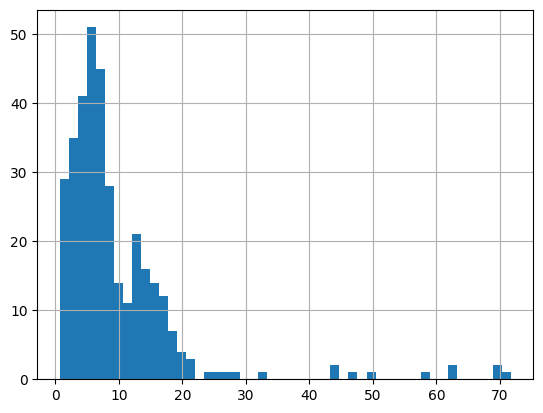

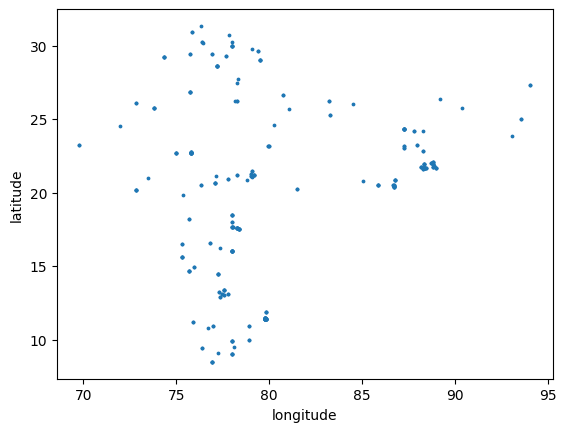

In [ ]:
df["value_avg"].hist(bins=50)
df.plot.scatter(x="longitude", y="latitude", s=3)

In [ ]:
df = df[df["lower_depth"] > df["upper_depth"]].copy()
df["thickness"] = df["lower_depth"] - df["upper_depth"]
df["year"] = df["date"].astype(str).str[:4]

profiles = df.groupby("profile_id").apply(
    lambda g: pd.Series({
        "latitude": g["latitude"].iloc[0],
        "longitude": g["longitude"].iloc[0],
        "year": g["year"].iloc[0],
        "positional_uncertainty": g["positional_uncertainty"].iloc[0],
        "soc": (g["value_avg"] * g["thickness"]).sum() / g["thickness"].sum(),
    })
).reset_index()

print("Final profiles:", len(profiles))
print(profiles.describe())
profiles.to_csv(path + "soc_profiles_clean.csv", index=False)

Final profiles: 197
         profile_id    latitude   longitude         soc
count  1.970000e+02  197.000000  197.000000  197.000000
mean   1.406906e+06   20.573667   79.948158    8.929737
std    1.416287e+05    5.949760    5.072226   10.035213
min    1.144115e+06    8.483333   69.800000    1.100000
25%    1.284411e+06   16.200000   76.916667    3.900000
50%    1.388533e+06   21.241667   78.000000    6.000000
75%    1.493003e+06   24.295833   81.483333    9.872222
max    1.691915e+06   31.333333   94.050000   71.700000


/tmp/ipykernel_4497/3978431457.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  profiles = df.groupby("profile_id").apply(


In [ ]:
print(profiles["year"].value_counts().sort_index())
print()
print(profiles["positional_uncertainty"].value_counts(dropna=False).head(10))

year
1968     8
1971     3
1972    20
1976     3
1977     2
1978     1
1979    80
1980    11
1982    12
1988     9
1990    18
1997     1
2002     3
2006     3
2010     8
2011     7
2014     6
????     2
Name: count, dtype: int64

positional_uncertainty
Over 10 km      149
Circa 100 m      33
1 km - 10 km     15
Name: count, dtype: int64


In [ ]:
profiles["unc_km"] = profiles["positional_uncertainty"].map(
    {"Circa 100 m": 0.1, "1 km - 10 km": 5, "Over 10 km": 10}
)
profiles.to_csv(path + "soc_profiles_clean.csv", index=False)
print(profiles["unc_km"].value_counts())

unc_km
10.0    149
0.1      33
5.0      15
Name: count, dtype: int64


In [ ]:
profiles["soc_pct"] = profiles["soc"] / 10
profiles.to_csv(path + "soc_profiles_clean.csv", index=False)
print(profiles["soc_pct"].describe())

count    197.000000
mean       0.892974
std        1.003521
min        0.110000
25%        0.390000
50%        0.600000
75%        0.987222
max        7.170000
Name: soc_pct, dtype: float64


In [ ]:
import ee
ee.Authenticate()
ee.Initialize(project="soc-mini-project-515519")
print("Earth Engine works")

EEException: Project soc-mini-project-515519 is not registered to use Earth Engine. Visit https://console.cloud.google.com/earth-engine/configuration?project=soc-mini-project-515519 to register your project. See https://developers.google.com/earth-engine/guides/access for more details.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = "/content/drive/MyDrive/SOC_Project/"
print(os.listdir(path))

Mounted at /content/drive
['wosis_202312_orgc.tsv', 'wosis_202312_profiles.tsv', 'soc_profiles_clean.csv']


In [ ]:
import pandas as pd

profiles = pd.read_csv(path + "soc_profiles_clean.csv")
print(profiles.shape)
print(profiles.head())

(197, 8)
   profile_id   latitude  longitude  year positional_uncertainty        soc  \
0     1144115   9.900000  78.000000  1990             Over 10 km   4.152174   
1     1144926  23.050000  87.250000  1979             Over 10 km   2.700000   
2     1144928  10.933333  78.933333  1979             Over 10 km   9.000000   
3     1144929   9.900000  78.000000  1990             Over 10 km   3.956522   
4     1170688  20.482975  86.687927  2014            Circa 100 m  10.500000   

   unc_km   soc_pct  
0    10.0  0.415217  
1    10.0  0.270000  
2    10.0  0.900000  
3    10.0  0.395652  
4     0.1  1.050000  


In [ ]:
oc = pd.read_csv(path + "wosis_202312_orgc.tsv", sep="\t", low_memory=False)

d = oc[oc["country_name"] == "India"].copy()
d = d.dropna(subset=["latitude", "longitude", "value_avg"])
d = d[(d["value_avg"] >= 0) & (d["lower_depth"] > d["upper_depth"]) & (d["upper_depth"] < 30)]

d["top"] = d["upper_depth"].clip(lower=0)
d["bot"] = d["lower_depth"].clip(upper=30)
d["thickness"] = d["bot"] - d["top"]

print("Profiles now:", d["profile_id"].nunique())

Profiles now: 202


In [ ]:
d = d[d["thickness"] > 0].copy()
d["w"] = d["value_avg"] * d["thickness"]
d["year"] = d["date"].astype(str).str[:4]

profiles2 = d.groupby("profile_id").agg(
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    year=("year", "first"),
    positional_uncertainty=("positional_uncertainty", "first"),
    w=("w", "sum"),
    t=("thickness", "sum"),
).reset_index()

profiles2["soc"] = profiles2["w"] / profiles2["t"]
profiles2 = profiles2.drop(columns=["w", "t"])
profiles2["unc_km"] = profiles2["positional_uncertainty"].map(
    {"Circa 100 m": 0.1, "1 km - 10 km": 5, "Over 10 km": 10}
)
profiles2["soc_pct"] = profiles2["soc"] / 10

print(len(profiles2))
print(profiles2["unc_km"].value_counts())
profiles2.to_csv(path + "soc_profiles_clean_v2.csv", index=False)

202
unc_km
10.0    154
0.1      33
5.0      15
Name: count, dtype: int64


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/SOC_Project/"
x = pd.read_csv(path + "ResultTable.csv")
print(x.shape)
print(list(x.columns))
print(x.head())

(50, 6)
['Sr.No', 'Sample No', 'Latitude', 'Longitude', 'Titration Reading', '% of Carbon Content in Soil Sample                      ']
   Sr.No    Sample No   Latitude  Longitude  Titration Reading  \
0      1  Sample No-1  17.994791  73.261516               7.19   
1      2  Sample No-2  17.994905  73.261465               6.68   
2      3  Sample No-3  17.994773  73.261430               6.07   
3      4  Sample No-4  17.994766  73.261522               6.39   
4      5  Sample No-5  17.994713  73.261524               7.01   

   % of Carbon Content in Soil Sample                        
0                                          13.862282         
1                                          14.047961         
2                                          14.270049         
3                                          14.153544         
4                                          13.927816         


In [ ]:
import numpy as np
c = x.columns[-1]
print(x[c].describe())
lat_m = (x["Latitude"].max() - x["Latitude"].min()) * 111000
lon_m = (x["Longitude"].max() - x["Longitude"].min()) * 111000 * np.cos(np.radians(18))
print("Spread: about", round(lat_m), "m north-south,", round(lon_m), "m east-west")

count    50.000000
mean     13.911432
std       0.176127
min      13.512767
25%      13.824964
50%      13.922354
75%      14.006092
max      14.270049
Name: % of Carbon Content in Soil Sample                      , dtype: float64
Spread: about 62 m north-south, 57 m east-west


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/SOC_Project/"
f = path + "11-9 Katghora Soil parameters.xlsx"

xl = pd.ExcelFile(f)
print(xl.sheet_names)

x = pd.read_excel(f, sheet_name=xl.sheet_names[0])
print(x.shape)
print(list(x.columns))
print(x.head(10))

['Revised_756_Long', 'DESCRIPTIVE', 'Revised_252_Wide', 'Analysis', 'OC_Trend_Summary']
(756, 19)
['Plot_ID', 'Range_Code', 'Land_Use_System', 'Replication', 'Depth', 'Anchor_Sample_No', 'Anchor_Sample_Code', 'pH', 'EC', 'OC', 'N', 'P', 'K', 'S', 'B', 'Zn', 'Cu', 'Fe', 'Mn']
   Plot_ID  Range_Code Land_Use_System  Replication     Depth  \
0  KAT-001  Aitmanagar      Sal Forest            1   0-10 cm   
1  KAT-001  Aitmanagar      Sal Forest            1  10-20 cm   
2  KAT-001  Aitmanagar      Sal Forest            1  20-30 cm   
3  KAT-002  Aitmanagar      Sal Forest            2   0-10 cm   
4  KAT-002  Aitmanagar      Sal Forest            2  10-20 cm   
5  KAT-002  Aitmanagar      Sal Forest            2  20-30 cm   
6  KAT-003  Aitmanagar      Sal Forest            3   0-10 cm   
7  KAT-003  Aitmanagar      Sal Forest            3  10-20 cm   
8  KAT-003  Aitmanagar      Sal Forest            3  20-30 cm   
9  KAT-004  Aitmanagar      Sal Forest            4   0-10 cm   

   Ancho

In [ ]:
for s in xl.sheet_names:
    d = pd.read_excel(f, sheet_name=s)
    print("----", s, d.shape)
    print(list(d.columns)[:30])

print()
print("Plots:", x["Plot_ID"].nunique())
print("Anchor samples:", x["Anchor_Sample_No"].nunique())
print("Unique OC values per anchor and depth:")
print(x.groupby(["Anchor_Sample_No", "Depth"])["OC"].nunique().value_counts())

---- Revised_756_Long (756, 19)
['Plot_ID', 'Range_Code', 'Land_Use_System', 'Replication', 'Depth', 'Anchor_Sample_No', 'Anchor_Sample_Code', 'pH', 'EC', 'OC', 'N', 'P', 'K', 'S', 'B', 'Zn', 'Cu', 'Fe', 'Mn']
---- DESCRIPTIVE (20, 26)
['Unnamed: 0', 'Unnamed: 1', 'pH', 'pH.1', 'EC', 'EC.1', 'OC', 'OC.1', 'N', 'N.1', 'P', 'P.1', 'K', 'K.1', 'S', 'S.1', 'B', 'B.1', 'Zn', 'Zn.1', 'Cu', 'Cu.1', 'Fe', 'Fe.1', 'Mn', 'Mn.1']
---- Revised_252_Wide (252, 42)
['Plot_ID', 'Range_Code', 'Land_Use_System', 'Replication', 'Anchor_Sample_No', 'Anchor_Sample_Code', 'pH_0_10cm', 'EC_0_10cm', 'OC_0_10cm', 'N_0_10cm', 'P_0_10cm', 'K_0_10cm', 'S_0_10cm', 'B_0_10cm', 'Zn_0_10cm', 'Cu_0_10cm', 'Fe_0_10cm', 'Mn_0_10cm', 'pH_10_20cm', 'EC_10_20cm', 'OC_10_20cm', 'N_10_20cm', 'P_10_20cm', 'K_10_20cm', 'S_10_20cm', 'B_10_20cm', 'Zn_10_20cm', 'Cu_10_20cm', 'Fe_10_20cm', 'Mn_10_20cm']
---- Analysis (41, 52)
['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unname

In [ ]:
w = pd.read_excel(f, sheet_name="Revised_252_Wide")
print(list(w.columns)[30:])

for s in xl.sheet_names:
    d = pd.read_excel(f, sheet_name=s, header=None).astype(str)
    hit = d.apply(lambda c: c.str.contains(r"lat|lon|coord|gps|utm", case=False, regex=True)).any().any()
    print(s, "-> has location words:", hit)

['pH_20_30cm', 'EC_20_30cm', 'OC_20_30cm', 'N_20_30cm', 'P_20_30cm', 'K_20_30cm', 'S_20_30cm', 'B_20_30cm', 'Zn_20_30cm', 'Cu_20_30cm', 'Fe_20_30cm', 'Mn_20_30cm']
Revised_756_Long -> has location words: False
DESCRIPTIVE -> has location words: False
Revised_252_Wide -> has location words: False
Analysis -> has location words: True
OC_Trend_Summary -> has location words: False


In [ ]:
a = pd.read_excel(f, sheet_name="Analysis", header=None).astype(str)
mask = a.apply(lambda c: c.str.contains(r"latitude|longitude|coordinat|gps|utm", case=False, regex=True))
print(a[mask.any(axis=1)].loc[:, mask.any(axis=0)].head(20))
print("matches:", int(mask.sum().sum()))

Empty DataFrame
Columns: []
Index: []
matches: 0


In [ ]:
import pandas as pd
path = "/content/drive/MyDrive/SOC_Project/"

for name in ["S1.xlsx", "S2.xlsx"]:
    xl = pd.ExcelFile(path + name)
    print("=====", name, xl.sheet_names)
    for s in xl.sheet_names:
        d = pd.read_excel(path + name, sheet_name=s)
        print("--", s, d.shape)
        print("  location cols:", [c for c in d.columns if any(k in str(c).lower() for k in ["lat", "lon", "coord", "gps"])])
        print("  carbon cols:", [c for c in d.columns if "carbon" in str(c).lower() or str(c).lower() in ["oc", "soc"]])
        print("  all cols:", list(d.columns))

===== S1.xlsx ['Akole']
-- Akole (166, 23)
  location cols: []
  carbon cols: []
  all cols: ['Fig. S1. Raw data for physical and chemical properties of soils from Akole. ', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22']
===== S2.xlsx ['Soil data']
-- Soil data (292, 18)
  location cols: []
  carbon cols: []
  all cols: ['Fig. S2. Raw data for physical and chemical properties of soils from Nandurbar. ', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17']


In [ ]:
for name in ["S1.xlsx", "S2.xlsx"]:
    d = pd.read_excel(path + name, header=None)
    print("=====", name, d.shape)
    print(d.head(8).to_string())

===== S1.xlsx (167, 23)
                                                                             0               1          2           3             4        5          6             7         8         9         10         11      12    13           14               15                16               17               18                 19                 20                 21                 22
0  Fig. S1. Raw data for physical and chemical properties of soils from Akole.              NaN        NaN         NaN           NaN      NaN        NaN           NaN       NaN       NaN       NaN        NaN     NaN   NaN          NaN              NaN               NaN              NaN              NaN                NaN                NaN                NaN                NaN
1                                                                      Clusters  Sample Number    Latitude  Longidtude  Farmers Name      NaN        NaN  Village Name  Sand (%)  Silt (%)  Clay (%)    Texture  OC (%) 

In [ ]:
a = pd.read_excel(path + "S1.xlsx", header=1)
a.columns = a.columns.astype(str).str.strip()
a = a.rename(columns={"Latitude": "latitude", "Longidtude": "longitude",
                      "OC (%)": "soc_pct", "Village Name": "village"})
a = a[["Sample Number", "latitude", "longitude", "village", "soc_pct"]]
for c in ["latitude", "longitude", "soc_pct"]:
    a[c] = pd.to_numeric(a[c], errors="coerce")
a = a.dropna(subset=["latitude", "longitude", "soc_pct"])

print(len(a), "samples,", a["village"].nunique(), "villages")
print(a["soc_pct"].describe())
print("lat range:", a["latitude"].min(), a["latitude"].max())
print("lon range:", a["longitude"].min(), a["longitude"].max())

a.to_csv(path + "akole_clean.csv", index=False)

165 samples, 6 villages
count    165.000000
mean       0.454733
std        0.148619
min        0.156000
25%        0.331500
50%        0.430000
75%        0.560000
max        0.840000
Name: soc_pct, dtype: float64
lat range: 19.5373006 19.625872
lon range: 73.7078006 73.7674024


In [ ]:
w = pd.read_csv(path + "soc_profiles_clean_v2.csv")
a = pd.read_csv(path + "akole_clean.csv")

w2 = pd.DataFrame({
    "source": "WoSIS_India",
    "group": "WoSIS",
    "latitude": w["latitude"], "longitude": w["longitude"],
    "year": w["year"], "unc_km": w["unc_km"], "soc_pct": w["soc_pct"],
})
a2 = pd.DataFrame({
    "source": "Akole",
    "group": a["village"],
    "latitude": a["latitude"], "longitude": a["longitude"],
    "year": None, "unc_km": 0.01, "soc_pct": a["soc_pct"],
})

allp = pd.concat([w2, a2], ignore_index=True)
print(allp.shape)
print(allp["source"].value_counts())
print(allp.groupby("source")["soc_pct"].describe())
allp.to_csv(path + "soc_all_points.csv", index=False)

(367, 7)
source
WoSIS_India    202
Akole          165
Name: count, dtype: int64
             count      mean       std    min       25%       50%       75%  \
source                                                                        
Akole        165.0  0.454733  0.148619  0.156  0.331500  0.430000  0.560000   
WoSIS_India  202.0  0.815943  0.924167  0.060  0.362333  0.553167  0.924167   

              max  
source             
Akole        0.84  
WoSIS_India  7.17  


In [ ]:
allp = pd.read_csv(path + "soc_all_points.csv")

# 1. points sharing exactly the same coordinates
dup = allp.duplicated(subset=["latitude", "longitude"], keep=False)
print("Points sharing a location:", dup.sum())
print(allp[dup].groupby("source").size())

# 2. outliers
print(allp.sort_values("soc_pct", ascending=False).head(8)[["source", "latitude", "longitude", "year", "soc_pct"]])

# 3. coordinates inside India's bounding box
bad = allp[(allp["latitude"] < 6) | (allp["latitude"] > 37) | (allp["longitude"] < 68) | (allp["longitude"] > 98)]
print("Outside India box:", len(bad))

Points sharing a location: 132
source
WoSIS_India    132
dtype: int64
          source   latitude  longitude  year   soc_pct
170  WoSIS_India  22.021114  88.684593  2011  7.170000
12   WoSIS_India  22.019495  88.682549  2011  6.250000
83   WoSIS_India   9.400000  76.366667  1980  5.838333
163  WoSIS_India  11.430675  79.794792  2002  4.030000
50   WoSIS_India  29.633333  79.416667  1972  3.264000
38   WoSIS_India  29.633333  79.416667  1972  3.264000
28   WoSIS_India   9.083333  77.233333  1979  3.104000
22   WoSIS_India  30.700001  77.866699  1968  3.050667
Outside India box: 0


In [ ]:
allp = pd.read_csv(path + "soc_all_points.csv")
allp["year"] = pd.to_numeric(allp["year"], errors="coerce")

before = len(allp)
allp = allp.drop_duplicates(subset=["source", "latitude", "longitude", "year", "soc_pct"])
print("Removed exact duplicates:", before - len(allp))

allp["lat_r"] = allp["latitude"].round(4)
allp["lon_r"] = allp["longitude"].round(4)

u = allp.groupby(["source", "lat_r", "lon_r"], as_index=False).agg(
    group=("group", "first"),
    latitude=("latitude", "first"),
    longitude=("longitude", "first"),
    year=("year", "min"),
    unc_km=("unc_km", "max"),
    soc_pct=("soc_pct", "mean"),
    n_merged=("soc_pct", "size"),
).drop(columns=["lat_r", "lon_r"])

print("Unique locations:", len(u))
print(u["source"].value_counts())
print(u["n_merged"].value_counts().sort_index())
u.to_csv(path + "soc_points_unique.csv", index=False)

Removed exact duplicates: 47
Unique locations: 293
source
Akole          165
WoSIS_India    128
Name: count, dtype: int64
n_merged
1    275
2     12
3      4
4      1
5      1
Name: count, dtype: int64


In [ ]:
import pandas as pd
path = "/content/drive/MyDrive/SOC_Project/"

s = pd.read_csv(path + "sample_identifier.csv")
print(s.shape)
print(list(s.columns))
print(s.head(8).to_string())

loc = [c for c in s.columns if any(k in str(c).lower() for k in ["lat", "lon", "geo", "gps"])]
print("location cols:", loc)
if len(loc) >= 2:
    print("unique location pairs:", s[loc[:2]].drop_duplicates().shape[0], "of", len(s), "rows")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/SOC_Project/sample_identifier.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = "/content/drive/MyDrive/SOC_Project/"
print(os.listdir(path))

Mounted at /content/drive
['wosis_202312_orgc.tsv', 'wosis_202312_profiles.tsv', 'soc_profiles_clean.csv', 'soc_profiles_clean_v2.csv', 'ResultTable.csv', '11-9 Katghora Soil parameters.xlsx', 'S1.xlsx', 'S2.xlsx', 'akole_clean.csv', 'soc_all_points.csv', 'soc_points_unique.csv', 'README-1.md', 'sample_identifier.csv', 'soil_sampling_protocol_SIS-Bihar.pdf']


In [ ]:
import pandas as pd
path = "/content/drive/MyDrive/SOC_Project/"

print(open(path + "README-1.md", encoding="utf-8", errors="ignore").read())
print("=" * 60)

s = pd.read_csv(path + "sample_identifier.csv")
print(s.shape)
print(list(s.columns))
print(s.head(8).to_string())

loc = [c for c in s.columns if any(k in str(c).lower() for k in ["lat", "lon", "geo", "gps"])]
print("location cols:", loc)
if len(loc) >= 2:
    print("unique location pairs:", s[loc[:2]].drop_duplicates().shape[0], "of", len(s), "rows")

﻿# India Soil Intelligence System (SIS-India): MIR Spectral Library and Soil Attribute database


## Introduction


The India Soil Intelligence System (SIS-India) MIR dataset is a library of paired dry and wet chemistry measurements of soil samples extracted from Bihar, India, in the years 2018, 2019, and 2020. The dataset is used for the training and evaluation of machine learning models for predicting soil properties from dry chemistry. It  consists of 3183 records, labeled with unique integer IDs indexed from 0 to 3182. Each record is comprised of the following three components:


* MIR spectrogram in csv format (dry chemistry), and
* wet chemistry measurements for each analyte, measured using the protocols of the SIS labs. 


Note that each soil sample has two replicate scans, referred to as different "versions" of the sample's spectrum either 0 or 1.




## Dry Chemistry


The `drychem/` file contains MIR spectral data in CSV format. The spectra are named using the scheme where co

In [ ]:
m = pd.read_csv(path + "sample_identifier.csv")
w = pd.read_csv(path + "wetchem.csv")
b = m.merge(w[["id", "OC"]], on="id")

print(b.shape)
print(b["OC"].describe())
print(b["District"].value_counts())
print(b["Year"].value_counts())
print(b.isna().sum())

(3183, 7)
count    3183.000000
mean        0.575156
std         0.194420
min         0.086538
25%         0.443878
50%         0.569444
75%         0.705035
max         1.917073
Name: OC, dtype: float64
District
Madhubani         207
Darbhanga         194
Begusarai         190
Munger            186
Jamui             178
Sitamarhi         177
Lakhisarai        151
Bhojpur           149
Mujjafarpur       148
Banka             146
Saharsa           144
Nalanda           143
Khagaria          140
Madhepura         137
Patna             136
Buxar             134
Samastipur        128
Araria            114
Nawada            106
Rohtas            101
Kishanganj         90
Purnia             35
East Champaran     29
EastChamparan      20
Name: count, dtype: int64
Year
2019    1816
2018     767
2020     600
Name: count, dtype: int64
id             0
original_id    0
Year           0
District       0
Latitude       0
Longitude      0
OC             0
dtype: int64


In [ ]:
m = pd.read_csv(path + "sample_identifier.csv")
w = pd.read_csv(path + "wetchem.csv")
b = m.merge(w[["id", "OC"]], on="id")

b["District"] = b["District"].replace({"Mujjafarpur": "Muzaffarpur",
                                       "EastChamparan": "East Champaran"})
print(b["District"].nunique(), "districts")

u = b.groupby(["Latitude", "Longitude"], as_index=False).agg(
    group=("District", "first"),
    year=("Year", "min"),
    soc_pct=("OC", "mean"),
    n_merged=("OC", "size"),
).rename(columns={"Latitude": "latitude", "Longitude": "longitude"})
u["source"] = "SIS_Bihar"
u["unc_km"] = 1.0

print(len(u), "unique locations")
print(u["soc_pct"].describe())
u.to_csv(path + "bihar_clean.csv", index=False)

23 districts
1347 unique locations
count    1347.000000
mean        0.581650
std         0.170096
min         0.091837
25%         0.470801
50%         0.579439
75%         0.695577
max         1.917073
Name: soc_pct, dtype: float64


In [ ]:
w = pd.read_csv(path + "soc_points_unique.csv")   # WoSIS + Akole
b = pd.read_csv(path + "bihar_clean.csv")

cols = ["source", "group", "latitude", "longitude", "year", "unc_km", "soc_pct", "n_merged"]
allp = pd.concat([w[cols], b[cols]], ignore_index=True)

print(allp.shape)
print(allp["source"].value_counts())
print(allp.groupby("source")["soc_pct"].describe()[["count", "mean", "std", "min", "max"]])
allp.to_csv(path + "soc_master.csv", index=False)

(1640, 8)
source
SIS_Bihar      1347
Akole           165
WoSIS_India     128
Name: count, dtype: int64
              count      mean       std       min       max
source                                                     
Akole         165.0  0.454733  0.148619  0.156000  0.840000
SIS_Bihar    1347.0  0.581650  0.170096  0.091837  1.917073
WoSIS_India   128.0  0.927019  1.087301  0.060000  7.170000


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import ee
ee.Authenticate()
ee.Initialize(project="soc-mini-project-515519")
print("Earth Engine works")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine works


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import ee
try:
    ee.Initialize(project="soc-mini-project-515519")
except Exception:
    ee.Authenticate()
    ee.Initialize(project="soc-mini-project-515519")
print("Earth Engine works")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Earth Engine works


In [ ]:
import pandas as pd
path = "/content/drive/MyDrive/SOC_Project/"

df = pd.read_csv(path + "soc_master.csv")
df["pid"] = range(len(df))

yr = pd.to_numeric(df["year"], errors="coerce")
df["ref_year"] = yr.where(yr.between(2018, 2020), 2020).astype(int)
df["buffer_m"] = (df["unc_km"].fillna(10) * 1000).clip(lower=30, upper=5000)
print(df.shape)

(1640, 11)


In [ ]:
def make_image(year):
    start, end = f"{year}-04-01", f"{year}-06-01"

    s2 = (ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
          .filterDate(start, end)
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
          .median().select(["B2","B3","B4","B8","B11","B12"]).divide(10000)
          .rename(["blue","green","red","nir","swir1","swir2"]))
    ndvi = s2.normalizedDifference(["nir","red"]).rename("ndvi")
    bsi = s2.expression("(S+R-N-B)/(S+R+N+B)",
          {"S": s2.select("swir1"), "R": s2.select("red"),
           "N": s2.select("nir"), "B": s2.select("blue")}).rename("bsi")

    s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
          .filterDate(start, end)
          .filter(ee.Filter.eq("instrumentMode", "IW"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
          .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
          .select(["VV","VH"]).median())

    terrain = ee.Terrain.products(ee.Image("USGS/SRTMGL1_003")).select(["elevation","slope"])
    rain = (ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
            .filterDate("2015-01-01", "2021-01-01").sum().divide(6).rename("rain_mm_yr"))
    temp = (ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
            .filterDate("2015-01-01", "2021-01-01").select("temperature_2m")
            .mean().subtract(273.15).rename("temp_c"))

    return ee.Image.cat([s2, ndvi, bsi, s1, terrain, rain, temp])

In [ ]:
def extract(sub, chunk=50):
    rows = []
    for y, g in sub.groupby("ref_year"):
        img = make_image(int(y))
        for i in range(0, len(g), chunk):
            c = g.iloc[i:i+chunk]
            feats = [ee.Feature(ee.Geometry.Point([r.longitude, r.latitude]).buffer(float(r.buffer_m)),
                                {"pid": int(r.pid)}) for r in c.itertuples()]
            out = img.reduceRegions(collection=ee.FeatureCollection(feats),
                                    reducer=ee.Reducer.mean(), scale=30, tileScale=4).getInfo()
            rows += [f["properties"] for f in out["features"]]
            print("done", len(rows))
    return pd.DataFrame(rows)

test = extract(df.sample(20, random_state=1))
print(test.head())
print(test.isna().sum())

done 5
done 15
done 20
          VH         VV      blue       bsi  elevation     green      ndvi  \
0 -20.705476 -12.223500  0.152614  0.115323  71.279718  0.150599  0.131552   
1 -18.583086 -10.689482  0.146276  0.091535  45.943742  0.142163  0.145068   
2 -20.677722 -11.685149  0.142957  0.066529  57.943196  0.135854  0.088353   
3 -17.628435 -10.634734  0.149841 -0.024621  73.323262  0.140821  0.227683   
4 -20.878128 -12.440543  0.152585  0.098246  69.848857  0.152557  0.131738   

        nir   pid   rain_mm_yr       red     slope     swir1     swir2  \
0  0.227679   729  1094.575505  0.174808  1.824321  0.305534  0.233468   
1  0.208750   764  1187.411617  0.155218  2.164361  0.271740  0.199232   
2  0.177776  1053  1010.894985  0.148400  1.902121  0.218482  0.164723   
3  0.213707  1596  1318.499927  0.134638  1.738877  0.212766  0.145930   
4  0.216049  1630  1399.879529  0.166062  1.757816  0.284137  0.222513   

      temp_c  
0  25.677459  
1  25.634021  
2  25.700304  
3  

In [ ]:
import time

def extract(sub, chunk=25):
    rows = []
    for y, g in sub.groupby("ref_year"):
        img = make_image(int(y))
        for big, gg in g.groupby(g["buffer_m"] > 1000):
            scale = 100 if big else 30
            for i in range(0, len(gg), chunk):
                c = gg.iloc[i:i+chunk]
                feats = [ee.Feature(ee.Geometry.Point([r.longitude, r.latitude]).buffer(float(r.buffer_m)),
                                    {"pid": int(r.pid)}) for r in c.itertuples()]
                ok = False
                for attempt in range(3):
                    try:
                        out = img.reduceRegions(collection=ee.FeatureCollection(feats),
                                                reducer=ee.Reducer.mean(), scale=scale,
                                                tileScale=4).getInfo()
                        rows += [f["properties"] for f in out["features"]]
                        ok = True
                        break
                    except Exception as e:
                        print("retry", attempt + 1, str(e)[:120])
                        time.sleep(5)
                if not ok:
                    print("FAILED batch, pids:", list(c["pid"])[:5], "...")
                print("done", len(rows), "of", len(sub))
    return pd.DataFrame(rows)

feat = extract(df)
final = df.merge(feat, on="pid", how="left")
final.to_csv(path + "soc_features.csv", index=False)
print(final.shape)
print(final.isna().sum())

done 25 of 1640
done 50 of 1640
done 75 of 1640
done 100 of 1640
done 125 of 1640
done 150 of 1640
done 175 of 1640
done 200 of 1640
done 225 of 1640
done 250 of 1640
done 275 of 1640
done 300 of 1640
done 325 of 1640
done 350 of 1640
done 369 of 1640
done 394 of 1640
done 419 of 1640
done 444 of 1640
done 469 of 1640
done 494 of 1640
done 519 of 1640
done 544 of 1640
done 569 of 1640
done 594 of 1640
done 619 of 1640
done 644 of 1640
done 669 of 1640
done 694 of 1640
done 719 of 1640
done 744 of 1640
done 769 of 1640
done 794 of 1640
done 819 of 1640
done 844 of 1640
done 869 of 1640
done 894 of 1640
done 919 of 1640
done 944 of 1640
done 969 of 1640
done 994 of 1640
done 1019 of 1640
done 1044 of 1640
done 1069 of 1640
done 1094 of 1640
done 1119 of 1640
done 1134 of 1640
done 1159 of 1640
done 1184 of 1640
done 1209 of 1640
done 1234 of 1640
done 1259 of 1640
done 1284 of 1640
done 1309 of 1640
done 1334 of 1640
done 1359 of 1640
done 1384 of 1640
done 1409 of 1640
done 1434 of 1640

In [ ]:
final = pd.read_csv(path + "soc_features.csv")

miss = final[final["temp_c"].isna()]
print(miss[["source", "group", "latitude", "longitude"]])

from sklearn.neighbors import KNeighborsRegressor
ok = final[final["temp_c"].notna()]
knn = KNeighborsRegressor(n_neighbors=5).fit(ok[["latitude", "longitude"]], ok["temp_c"])
final.loc[miss.index, "temp_c"] = knn.predict(miss[["latitude", "longitude"]])
final["temp_filled"] = final.index.isin(miss.index)

final.to_csv(path + "soc_features.csv", index=False)
print(final.drop(columns="year").isna().sum().sum(), "missing values left")
print(final.groupby("source")[["soc_pct", "ndvi", "elevation", "rain_mm_yr", "temp_c"]].mean().round(2))

          source  group   latitude  longitude
176  WoSIS_India  WoSIS  11.397231  79.806656
177  WoSIS_India  WoSIS  11.419434  79.792336
178  WoSIS_India  WoSIS  11.429268  79.796646
179  WoSIS_India  WoSIS  11.430675  79.794792
180  WoSIS_India  WoSIS  11.445435  79.792503
206  WoSIS_India  WoSIS  20.379036  86.733482
207  WoSIS_India  WoSIS  20.381796  86.734795
228  WoSIS_India  WoSIS  21.570868  88.296623
229  WoSIS_India  WoSIS  21.574017  88.292671
0 missing values left
             soc_pct  ndvi  elevation  rain_mm_yr  temp_c
source                                                   
Akole           0.45  0.25     805.92     1294.08   23.22
SIS_Bihar       0.58  0.22      62.22     1319.42   25.21
WoSIS_India     0.93  0.27     292.61     1281.36   25.58


In [ ]:
chk = pd.read_csv(path + "soc_features.csv")
print(chk.shape)
print(chk["temp_filled"].sum(), "filled temperatures")

(1640, 26)
9 filled temperatures


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
path = "/content/drive/MyDrive/SOC_Project/"
print(os.listdir(path))

Mounted at /content/drive
['wosis_202312_orgc.tsv', 'wosis_202312_profiles.tsv', 'soc_profiles_clean.csv', 'soc_profiles_clean_v2.csv', 'ResultTable.csv', '11-9 Katghora Soil parameters.xlsx', 'S1.xlsx', 'S2.xlsx', 'akole_clean.csv', 'soc_all_points.csv', 'soc_points_unique.csv', 'README-1.md', 'sample_identifier.csv', 'soil_sampling_protocol_SIS-Bihar.pdf', 'wetchem.csv', 'bihar_clean.csv', 'soc_master.csv', 'soc_features.csv']


In [ ]:
import numpy as np
import pandas as pd
path = "/content/drive/MyDrive/SOC_Project/"

d = pd.read_csv(path + "soc_features.csv")

bih = d[d["source"] == "SIS_Bihar"]
sizes = bih["group"].value_counts()
eligible = sizes[sizes >= 40].index.to_numpy()      # skip the tiny districts
rng = np.random.default_rng(42)
test_districts = list(rng.choice(eligible, size=4, replace=False))

d["split"] = "wosis_test"
d.loc[d["source"] == "Akole", "split"] = "akole_test"
d.loc[d["source"] == "SIS_Bihar", "split"] = "bihar_trainval"
d.loc[(d["source"] == "SIS_Bihar") & d["group"].isin(test_districts), "split"] = "bihar_test"

print("Held-out Bihar districts:", test_districts)
print(d["split"].value_counts())
d.to_csv(path + "soc_split.csv", index=False)

Held-out Bihar districts: ['Madhubani', 'Banka', 'Bhojpur', 'Madhepura']
split
bihar_trainval    1082
bihar_test         265
akole_test         165
wosis_test         128
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd
path = "/content/drive/MyDrive/SOC_Project/"

d = pd.read_csv(path + "soc_split.csv")
feats = ["blue","green","red","nir","swir1","swir2","ndvi","bsi","VV","VH",
         "elevation","slope","rain_mm_yr","temp_c"]

tr = d[d["split"] == "bihar_trainval"].reset_index(drop=True)
X, y, g = tr[feats], tr["soc_pct"], tr["group"]
print(len(tr), "points,", g.nunique(), "districts")

Mounted at /content/drive
1082 points, 19 districts


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=0)
pred = cross_val_predict(rf, X, y, groups=g, cv=LeaveOneGroupOut())
base = np.array([y[g != gg].mean() for gg in g])

def rep(name, p):
    print(name, "RMSE", round(mean_squared_error(y, p) ** 0.5, 3),
          "MAE", round(mean_absolute_error(y, p), 3),
          "R2", round(r2_score(y, p), 3),
          "bias", round(float((p - y).mean()), 3))
rep("Baseline (mean only)", base)
rep("Random Forest      ", pred)

rf.fit(X, y)
print(pd.Series(rf.feature_importances_, feats).sort_values(ascending=False).head(6).round(3))

Baseline (mean only) RMSE 0.168 MAE 0.133 R2 -0.02 bias -0.0
Random Forest       RMSE 0.172 MAE 0.136 R2 -0.07 bias -0.0
temp_c        0.140
rain_mm_yr    0.090
slope         0.090
swir1         0.084
swir2         0.081
elevation     0.077
dtype: float64


In [ ]:
from sklearn.model_selection import KFold

def cv_eval(cols, cv, groups=None):
    p = cross_val_predict(RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                          n_jobs=-1, random_state=0), tr[cols], y, groups=groups, cv=cv)
    return round(r2_score(y, p), 3), round(mean_squared_error(y, p) ** 0.5, 3)

no_clim = [f for f in feats if f not in ["temp_c", "rain_mm_yr"]]
print("All features,  random 5-fold  (R2, RMSE):", cv_eval(feats, KFold(5, shuffle=True, random_state=0)))
print("All features,  leave-district (R2, RMSE):", cv_eval(feats, LeaveOneGroupOut(), g))
print("No climate,    random 5-fold  (R2, RMSE):", cv_eval(no_clim, KFold(5, shuffle=True, random_state=0)))
print("No climate,    leave-district (R2, RMSE):", cv_eval(no_clim, LeaveOneGroupOut(), g))

All features,  random 5-fold  (R2, RMSE): (0.145, 0.154)
All features,  leave-district (R2, RMSE): (-0.055, 0.171)
No climate,    random 5-fold  (R2, RMSE): (0.106, 0.157)
No climate,    leave-district (R2, RMSE): (-0.062, 0.172)


In [ ]:
from sklearn.model_selection import KFold, train_test_split
alpha = 0.10

def split_conformal(Xtr, ytr, Xte, seed=0):
    Xa, Xc, ya, yc = train_test_split(Xtr, ytr, test_size=0.25, random_state=seed)
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                              n_jobs=-1, random_state=seed).fit(Xa, ya)
    s = np.abs(yc - m.predict(Xc))
    n = len(s)
    q = np.quantile(s, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n), method="higher")
    p = m.predict(Xte)
    return p - q, p + q

def report(name, lo, hi):
    inside = (y.values >= lo) & (y.values <= hi)
    print(name, "coverage", round(inside.mean(), 3), "| mean width", round((hi - lo).mean(), 3))
    return inside

# 1) random 5-fold
lo = np.zeros(len(tr)); hi = np.zeros(len(tr))
for a, b in KFold(5, shuffle=True, random_state=0).split(X):
    lo[b], hi[b] = split_conformal(X.iloc[a], y.iloc[a], X.iloc[b])
report("Random 5-fold     ", lo, hi)

# 2) leave one district out
lo2 = np.zeros(len(tr)); hi2 = np.zeros(len(tr))
for dist in g.unique():
    te = (g == dist).values
    lo2[te], hi2[te] = split_conformal(X[~te], y[~te], X[te])
inside = report("Leave-district-out", lo2, hi2)

per = pd.Series(inside).groupby(g.values).mean().sort_values()
print("\nCoverage by held-out district:")
print(per.round(2).to_string())

Random 5-fold      coverage 0.926 | mean width 0.557
Leave-district-out coverage 0.884 | mean width 0.527

Coverage by held-out district:
Munger            0.79
Kishanganj        0.81
East Champaran    0.81
Jamui             0.82
Buxar             0.83
Rohtas            0.83
Khagaria          0.86
Darbhanga         0.86
Patna             0.88
Samastipur        0.88
Nawada            0.90
Muzaffarpur       0.91
Saharsa           0.92
Nalanda           0.92
Purnia            0.94
Begusarai         0.94
Lakhisarai        0.95
Sitamarhi         0.95
Araria            0.97


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
alpha = 0.10

def conformal(method, Xtr, ytr, Xte, seed=0):
    Xa, Xc, ya, yc = train_test_split(Xtr, ytr, test_size=0.25, random_state=seed)
    n = len(yc)
    lvl = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    if method == "mean":
        mu = ya.mean()
        q = np.quantile(np.abs(yc - mu), lvl, method="higher")
        return np.full(len(Xte), mu - q), np.full(len(Xte), mu + q)
    if method == "rf":
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                  n_jobs=-1, random_state=seed).fit(Xa, ya)
        q = np.quantile(np.abs(yc - m.predict(Xc)), lvl, method="higher")
        p = m.predict(Xte)
        return p - q, p + q
    if method == "cqr":
        kw = dict(loss="quantile", n_estimators=150, max_depth=3, learning_rate=0.05,
                  subsample=0.8, random_state=seed)
        lo_m = GradientBoostingRegressor(alpha=alpha / 2, **kw).fit(Xa, ya)
        hi_m = GradientBoostingRegressor(alpha=1 - alpha / 2, **kw).fit(Xa, ya)
        s = np.maximum(lo_m.predict(Xc) - yc, yc - hi_m.predict(Xc))
        q = np.quantile(s, lvl, method="higher")
        return lo_m.predict(Xte) - q, hi_m.predict(Xte) + q

def interval_score(yv, lo, hi):
    return (hi - lo) + (2 / alpha) * np.maximum(lo - yv, 0) + (2 / alpha) * np.maximum(yv - hi, 0)

yv = y.values
for method in ["mean", "rf", "cqr"]:
    lo = np.zeros(len(tr)); hi = np.zeros(len(tr))
    for dist in g.unique():
        te = (g == dist).values
        lo[te], hi[te] = conformal(method, X[~te], y[~te], X[te])
    inside = (yv >= lo) & (yv <= hi)
    per = pd.Series(inside).groupby(g.values).mean()
    print(f"{method:5s} coverage {inside.mean():.3f} | width {(hi - lo).mean():.3f} | "
          f"interval score {interval_score(yv, lo, hi).mean():.3f} | "
          f"worst district {per.min():.2f}")

mean  coverage 0.915 | width 0.582 | interval score 0.696 | worst district 0.80
rf    coverage 0.884 | width 0.527 | interval score 0.703 | worst district 0.79
cqr   coverage 0.909 | width 0.562 | interval score 0.682 | worst district 0.75


In [ ]:
res = []
for seed in range(5):
    for method in ["mean", "rf", "cqr"]:
        lo = np.zeros(len(tr)); hi = np.zeros(len(tr))
        for dist in g.unique():
            te = (g == dist).values
            lo[te], hi[te] = conformal(method, X[~te], y[~te], X[te], seed=seed)
        inside = (yv >= lo) & (yv <= hi)
        res.append((method, seed, inside.mean(), (hi - lo).mean(),
                    interval_score(yv, lo, hi).mean()))

r = pd.DataFrame(res, columns=["method", "seed", "coverage", "width", "score"])
print(r.groupby("method")[["coverage", "width", "score"]].agg(["mean", "std"]).round(3))

       coverage         width         score       
           mean    std   mean    std   mean    std
method                                            
cqr       0.899  0.010  0.549  0.011  0.685  0.006
mean      0.905  0.013  0.571  0.017  0.700  0.005
rf        0.870  0.011  0.519  0.014  0.717  0.013


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

def conformal2(method, Xtr, ytr, Xte, seed=0, gtr=None):
    if gtr is None:
        Xa, Xc, ya, yc = train_test_split(Xtr, ytr, test_size=0.25, random_state=seed)
    else:
        ia, ic = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
                      .split(Xtr, ytr, gtr))
        Xa, Xc, ya, yc = Xtr.iloc[ia], Xtr.iloc[ic], ytr.iloc[ia], ytr.iloc[ic]
    n = len(yc)
    lvl = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    if method == "mean":
        mu = ya.mean()
        q = np.quantile(np.abs(yc - mu), lvl, method="higher")
        return np.full(len(Xte), mu - q), np.full(len(Xte), mu + q)
    if method == "rf":
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                  n_jobs=-1, random_state=seed).fit(Xa, ya)
        q = np.quantile(np.abs(yc - m.predict(Xc)), lvl, method="higher")
        p = m.predict(Xte)
        return p - q, p + q
    if method == "cqr":
        kw = dict(loss="quantile", n_estimators=150, max_depth=3, learning_rate=0.05,
                  subsample=0.8, random_state=seed)
        lo_m = GradientBoostingRegressor(alpha=alpha / 2, **kw).fit(Xa, ya)
        hi_m = GradientBoostingRegressor(alpha=1 - alpha / 2, **kw).fit(Xa, ya)
        s = np.maximum(lo_m.predict(Xc) - yc, yc - hi_m.predict(Xc))
        q = np.quantile(s, lvl, method="higher")
        return lo_m.predict(Xte) - q, hi_m.predict(Xte) + q

res = []
for seed in range(5):
    for method in ["mean", "rf", "cqr"]:
        lo = np.zeros(len(tr)); hi = np.zeros(len(tr))
        for dist in g.unique():
            te = (g == dist).values
            lo[te], hi[te] = conformal2(method, X[~te], y[~te], X[te], seed=seed, gtr=g[~te])
        inside = (yv >= lo) & (yv <= hi)
        res.append((method, seed, inside.mean(), (hi - lo).mean(),
                    interval_score(yv, lo, hi).mean()))

r2 = pd.DataFrame(res, columns=["method", "seed", "coverage", "width", "score"])
print("Spatially blocked calibration:")
print(r2.groupby("method")[["coverage", "width", "score"]].agg(["mean", "std"]).round(3))

Spatially blocked calibration:
       coverage         width         score       
           mean    std   mean    std   mean    std
method                                            
cqr       0.912  0.009  0.572  0.011  0.694  0.005
mean      0.912  0.011  0.582  0.017  0.702  0.004
rf        0.913  0.010  0.586  0.014  0.713  0.008


In [9]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, time, ee
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score

path = "/content/drive/MyDrive/SOC_Project/"
d = pd.read_csv(path + "soc_split.csv")
feats = ["blue","green","red","nir","swir1","swir2","ndvi","bsi","VV","VH",
         "elevation","slope","rain_mm_yr","temp_c"]

try:
    ee.Initialize(project="soc-mini-project-515519")
except Exception:
    ee.Authenticate()
    ee.Initialize(project="soc-mini-project-515519")
print(d.shape, "| Earth Engine works")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1640, 27) | Earth Engine works


In [12]:
soc = (ee.Image("projects/soilgrids-isric/soc_mean")
       .select(["soc_0-5cm_mean", "soc_5-15cm_mean", "soc_15-30cm_mean"])
       .rename(["sg_soc_0_5", "sg_soc_5_15", "sg_soc_15_30"]))
clay = (ee.Image("projects/soilgrids-isric/clay_mean")
        .select(["clay_0-5cm_mean", "clay_5-15cm_mean", "clay_15-30cm_mean"])
        .rename(["sg_clay_0_5", "sg_clay_5_15", "sg_clay_15_30"]))
sg_img = ee.Image.cat([soc, clay])

rows = []
for i in range(0, len(d), 100):
    c = d.iloc[i:i + 100]
    feats_ee = [ee.Feature(ee.Geometry.Point([r.longitude, r.latitude])
                           .buffer(float(max(r.buffer_m, 250))), {"pid": int(r.pid)})
                for r in c.itertuples()]
    for attempt in range(3):
        try:
            out = sg_img.reduceRegions(collection=ee.FeatureCollection(feats_ee),
                                       reducer=ee.Reducer.mean(), scale=250,
                                       tileScale=4).getInfo()
            rows += [f["properties"] for f in out["features"]]
            break
        except Exception as e:
            print("retry", attempt + 1, str(e)[:100]); time.sleep(5)
    print("done", len(rows), "of", len(d))

sg = pd.DataFrame(rows)
d2 = d.merge(sg, on="pid", how="left")
# SoilGrids is in dg/kg: depth-weighted 0-30 cm, then /100 to get %
d2["sg_soc_pct"] = (5 * d2["sg_soc_0_5"] + 10 * d2["sg_soc_5_15"] + 15 * d2["sg_soc_15_30"]) / 30 / 100
d2.to_csv(path + "soc_split_sg.csv", index=False)

print(d2[["sg_soc_pct", "sg_clay_0_5"]].isna().sum())
print(d2.groupby("source")[["soc_pct", "sg_soc_pct"]].mean().round(2))

done 100 of 1640
done 200 of 1640
done 300 of 1640
done 400 of 1640
done 500 of 1640
done 600 of 1640
done 700 of 1640
done 800 of 1640
done 900 of 1640
done 1000 of 1640
done 1100 of 1640
done 1200 of 1640
done 1300 of 1640
done 1400 of 1640
done 1500 of 1640
done 1600 of 1640
done 1640 of 1640
sg_soc_pct     22
sg_clay_0_5    20
dtype: int64
             soc_pct  sg_soc_pct
source                          
Akole           0.45        1.81
SIS_Bihar       0.58        1.25
WoSIS_India     0.93        1.46


In [13]:
from scipy.stats import spearmanr

tr2 = d2[d2["split"] == "bihar_trainval"].reset_index(drop=True)
y2, g2 = tr2["soc_pct"], tr2["group"]
ok = tr2["sg_soc_pct"].notna()

print("SoilGrids alone        R2", round(r2_score(y2[ok], tr2.loc[ok, "sg_soc_pct"]), 3),
      "| rank correlation", round(spearmanr(y2[ok], tr2.loc[ok, "sg_soc_pct"])[0], 3))

sg_cols = ["sg_soc_0_5", "sg_soc_5_15", "sg_soc_15_30",
           "sg_clay_0_5", "sg_clay_5_15", "sg_clay_15_30"]
for name, cols in [("Satellite only        ", feats), ("Satellite + SoilGrids  ", feats + sg_cols)]:
    Xc = tr2[cols].fillna(tr2[cols].median())
    p = cross_val_predict(RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                          n_jobs=-1, random_state=0), Xc, y2, groups=g2, cv=LeaveOneGroupOut())
    print(name, "leave-district  R2", round(r2_score(y2, p), 3),
          "RMSE", round(mean_squared_error(y2, p) ** 0.5, 3),
          "| rank correlation", round(spearmanr(y2, p)[0], 3))

SoilGrids alone        R2 -17.249 | rank correlation -0.044
Satellite only         leave-district  R2 -0.055 RMSE 0.171 | rank correlation 0.094
Satellite + SoilGrids   leave-district  R2 -0.028 RMSE 0.169 | rank correlation 0.125
